In [ ]:
# Installazione pacchetti
!pip install spacy pandas nltk openpyxl matplotlib seaborn

# Download modelli
!python -m spacy download it_core_news_md

import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')
import pandas as pd
import spacy
import nltk
from nltk.corpus import wordnet as wn
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Caricamento modello spaCy italiano
nlp = spacy.load('it_core_news_md')

print("✓ Librerie caricate con successo")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 19.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('it_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


✓ Librerie caricate con successo


#Preprocessing

In [ ]:
def preprocess_text(text):
    """Preprocessing con lemmatizzazione"""
    doc = nlp(text.lower())
    return [token.lemma_ for token in doc
            if not token.is_stop
            and not token.is_punct
            and token.is_alpha]

def get_italian_synonyms(term):
    """Ottiene sinonimi italiani da WordNet"""
    synsets = wn.synsets(term, lang='ita')
    synonyms = set()
    for syn in synsets:
        for lemma in syn.lemma_names('ita'):
            synonyms.add(lemma)
    return list(synonyms)

#Ricerca Synset

In [ ]:
def find_synsets_from_definition(definition, target_term, top_k=5, score_threshold=0.0):
    """
    Ricerca synset partendo da definizione italiana
    Usa approccio ibrido: keywords + semantic similarity
    """
    # Preprocessa definizione
    keywords = set(preprocess_text(definition))

    # Ottieni doc spaCy per similarity semantica
    def_doc = nlp(definition.lower())

    # Termini di ricerca: target + keywords + sinonimi target
    search_terms = {target_term.lower()}
    search_terms.update(keywords)
    search_terms.update(get_italian_synonyms(target_term))

    # Cerca synset candidati
    candidate_synsets = []
    seen_synsets = set()

    for term in search_terms:
        for syn in wn.synsets(term, lang='ita'):
            if syn.name() not in seen_synsets:
                candidate_synsets.append(syn)
                seen_synsets.add(syn.name())

    # Scoring dei synset
    scored_synsets = []

    for synset in candidate_synsets:
        # 1. Jaccard similarity con lemmi italiani
        synset_lemmas_ita = set([l.lower() for l in synset.lemma_names('ita')])
        synset_lemmas_eng = set([l.lower().replace('_', ' ') for l in synset.lemma_names('eng')])
        all_synset_lemmas = synset_lemmas_ita | synset_lemmas_eng

        jaccard = len(keywords & all_synset_lemmas) / len(keywords | all_synset_lemmas) if (keywords | all_synset_lemmas) else 0

        # 2. Semantic similarity con definizione WordNet
        # Usa la definizione inglese perché quella italiana spesso non c'è
        wn_def = synset.definition()
        wn_def_doc = nlp(wn_def) if wn_def else def_doc
        semantic_sim_def = def_doc.similarity(wn_def_doc)

        # 3. Semantic similarity con esempi
        example_sim = 0
        if synset.examples():
            examples_text = " ".join(synset.examples())
            example_doc = nlp(examples_text)
            example_sim = def_doc.similarity(example_doc)

        # 4. Boost se termine target è tra i lemmi italiani
        target_boost = 0.3 if target_term.lower() in synset_lemmas_ita else 0

        # 5. Boost per iperonimi rilevanti
        hypernym_boost = 0
        for hyper in synset.hypernyms():
            hyper_lemmas_ita = set([l.lower() for l in hyper.lemma_names('ita')])
            if len(keywords & hyper_lemmas_ita) > 0:
                hypernym_boost = 0.1
                break

        # 6. Overlap con lemmi WordNet processati
        wn_lemmas_text = " ".join(synset.lemma_names('ita') + synset.lemma_names('eng'))
        wn_doc = nlp(wn_lemmas_text.lower())
        wn_keywords = set([token.lemma_ for token in wn_doc if not token.is_stop and token.is_alpha])
        keyword_overlap = len(keywords & wn_keywords) / len(keywords | wn_keywords) if (keywords | wn_keywords) else 0

        # Score finale (pesato)
        final_score = (
            jaccard * 0.15 +
            keyword_overlap * 0.15 +
            semantic_sim_def * 0.35 +
            example_sim * 0.15 +
            target_boost +
            hypernym_boost
        )

        if final_score >= score_threshold:
            scored_synsets.append({
                'synset': synset,
                'name': synset.name(),
                'pos': synset.pos(),
                'definition': synset.definition(),
                'examples': synset.examples(),
                'lemmas_ita': synset.lemma_names('ita') if synset.lemma_names('ita') else [],
                'lemmas_eng': synset.lemma_names('eng'),
                'hypernyms': [(h.name(), h.lemma_names('ita')) for h in synset.hypernyms()],
                'hyponyms': [(h.name(), h.lemma_names('ita')) for h in synset.hyponyms()[:3]],
                'score': final_score,
                'score_breakdown': {
                    'jaccard': jaccard,
                    'keyword_overlap': keyword_overlap,
                    'semantic_def': semantic_sim_def,
                    'semantic_examples': example_sim,
                    'target_match': target_boost,
                    'hypernym': hypernym_boost
                }
            })

    # Ordina per score
    scored_synsets.sort(key=lambda x: x['score'], reverse=True)

    return scored_synsets[:top_k]


#Caricamento dati

In [ ]:
# Carica Excel
df = pd.read_excel('dataset_definizioni_TLN_25.xlsx')
df = df.iloc[:, :-2]

# Crea dizionario termine -> definizioni
term_dict = {
    row[1]: [x for x in row[2:] if pd.notna(x)]
    for row in df.values
}

print("\n" + "="*80)
print("DATASET CARICATO")
print("="*80)
for term, definitions in term_dict.items():
    print(f"  {term}: {len(definitions)} definizioni")


DATASET CARICATO
  Pantalone: 40 definizioni
  Microscopio: 39 definizioni
  Pericolo: 38 definizioni
  Euristica: 36 definizioni


#Analisi per singola definizione

In [ ]:
print("\n" + "="*80)
print("FASE 1: RICERCA ONOMASIOLOGICA PER SINGOLA DEFINIZIONE")
print("="*80)

all_results = {}

for term, definitions in term_dict.items():
    print(f"\n{'='*80}")
    print(f"TERMINE: {term.upper()}")
    print(f"{'='*80}")

    term_results = []

    for i, definition in enumerate(definitions, 1):
        print(f"\n--- Definizione {i}/{len(definitions)} ---")
        print(f"{definition}")

        # Ricerca synset
        synsets = find_synsets_from_definition(definition, term, top_k=5)

        if synsets:
            print(f"\n✓ Trovati {len(synsets)} synset candidati:\n")

            for rank, syn_info in enumerate(synsets, 1):
                print(f"  #{rank} - {syn_info['name']} (POS: {syn_info['pos']}) [Score: {syn_info['score']:.3f}]")
                print(f"       Definizione WN: {syn_info['definition']}")

                if syn_info['lemmas_ita']:
                    print(f"       Lemmi italiani: {', '.join(syn_info['lemmas_ita'])}")
                else:
                    print(f"       Lemmi italiani: [Non disponibili]")

                print(f"       Lemmi inglesi: {', '.join(syn_info['lemmas_eng'][:5])}")

                # Mostra score breakdown per il primo
                if rank == 1:
                    sb = syn_info['score_breakdown']
                    print(f"       Score breakdown:")
                    print(f"         - Jaccard (lemmi): {sb['jaccard']:.3f}")
                    print(f"         - Keyword overlap: {sb['keyword_overlap']:.3f}")
                    print(f"         - Semantic (def): {sb['semantic_def']:.3f}")
                    print(f"         - Semantic (esempi): {sb['semantic_examples']:.3f}")
                    print(f"         - Target match: {sb['target_match']:.3f}")
                    print(f"         - Hypernym: {sb['hypernym']:.3f}")

                if syn_info['hypernyms']:
                    hyper_str = ', '.join([f"{name} ({', '.join(lemmas_ita) if lemmas_ita else 'N/A'})"
                                          for name, lemmas_ita in syn_info['hypernyms'][:2]])
                    print(f"       Iperonimi: {hyper_str}")

                if syn_info['examples']:
                    print(f"       Esempi WN: {syn_info['examples'][0]}")
                print()
        else:
            print("  ✗ Nessun synset trovato\n")

        term_results.append({
            'definition': definition,
            'synsets': synsets
        })

    all_results[term] = term_results


FASE 1: RICERCA ONOMASIOLOGICA PER SINGOLA DEFINIZIONE

TERMINE: PANTALONE

--- Definizione 1/40 ---
Indumento per la parte inferiore del corpo umano

✓ Trovati 5 synset candidati:

  #1 - body.n.03 (POS: n) [Score: 0.106]
       Definizione WN: a natural object consisting of a dead animal or person
       Lemmi italiani: cadavere, corpo, morto
       Lemmi inglesi: body, dead_body
       Score breakdown:
         - Jaccard (lemmi): 0.125
         - Keyword overlap: 0.143
         - Semantic (def): 0.213
         - Semantic (esempi): -0.062
         - Target match: 0.000
         - Hypernym: 0.000
       Iperonimi: natural_object.n.01 (oggetto_naturale)
       Esempi WN: they found the body in the lake

  #2 - human.a.02 (POS: a) [Score: 0.074]
       Definizione WN: relating to a person
       Lemmi italiani: umano
       Lemmi inglesi: human
       Esempi WN: the experiment was conducted on 6 monkeys and 2 human subjects

  #3 - inferior.a.02 (POS: a) [Score: 0.070]
       Definizio

/tmp/ipython-input-1303477471.py:49: UserWarning: [W008] Evaluating Doc.similarity based on empty vectors.
  example_sim = def_doc.similarity(example_doc)



✓ Trovati 5 synset candidati:

  #1 - hazard.n.01 (POS: n) [Score: 0.364]
       Definizione WN: a source of danger; a possibility of incurring loss or misfortune
       Lemmi italiani: pericolo, rischio
       Lemmi inglesi: hazard, jeopardy, peril, risk, endangerment
       Score breakdown:
         - Jaccard (lemmi): 0.000
         - Keyword overlap: 0.000
         - Semantic (def): 0.101
         - Semantic (esempi): 0.193
         - Target match: 0.300
         - Hypernym: 0.000
       Iperonimi: danger.n.03 (pericolo)
       Esempi WN: drinking alcohol is a health hazard

  #2 - risk.n.02 (POS: n) [Score: 0.338]
       Definizione WN: a venture undertaken without regard to possible loss or injury
       Lemmi italiani: alea, pericolo, periglio, rischio
       Lemmi inglesi: risk, peril, danger
       Iperonimi: venture.n.01 (N/A)
       Esempi WN: he saw the rewards but not the risks of crime

  #3 - danger.n.03 (POS: n) [Score: 0.284]
       Definizione WN: a cause of pain or i

#Analisi aggregata per termine

In [ ]:
print("\n" + "="*80)
print("FASE 2: ANALISI AGGREGATA PER TERMINE")
print("="*80)

aggregate_results = {}

for term, definitions in term_dict.items():
    print(f"\n{'='*80}")
    print(f"TERMINE: {term.upper()}")
    print(f"{'='*80}")

    # Combina tutte le definizioni
    combined_definitions = " | ".join(definitions)

    print(f"Definizioni aggregate ({len(definitions)} definizioni)")
    print(f"Testo combinato: {combined_definitions[:200]}...\n")

    # Ricerca con definizione aggregata
    synsets = find_synsets_from_definition(combined_definitions, term, top_k=10)

    if synsets:
        print(f"✓ Trovati {len(synsets)} synset candidati:\n")

        # Conta quante volte ogni synset appare nei risultati individuali
        synset_frequency = Counter()
        for def_result in all_results[term]:
            for syn in def_result['synsets']:
                synset_frequency[syn['name']] += 1

        for rank, syn_info in enumerate(synsets, 1):
            freq = synset_frequency.get(syn_info['name'], 0)
            freq_pct = (freq / len(definitions)) * 100 if definitions else 0

            print(f"  #{rank} - {syn_info['name']} (POS: {syn_info['pos']})")
            print(f"       Score aggregato: {syn_info['score']:.3f}")
            print(f"       Frequenza nelle def. singole: {freq}/{len(definitions)} ({freq_pct:.0f}%)")
            print(f"       Definizione WN: {syn_info['definition']}")

            if syn_info['lemmas_ita']:
                print(f"       Lemmi italiani: {', '.join(syn_info['lemmas_ita'])}")
            else:
                print(f"       Lemmi italiani: [Non disponibili]")

            print(f"       Lemmi inglesi: {', '.join(syn_info['lemmas_eng'][:5])}")
            print()
    else:
        print("✗ Nessun synset trovato\n")

    aggregate_results[term] = synsets


FASE 2: ANALISI AGGREGATA PER TERMINE

TERMINE: PANTALONE
Definizioni aggregate (40 definizioni)
Testo combinato: Indumento per la parte inferiore del corpo umano | Indumento per le gambe, diviso per ogni gamba può essere lungo o corto e di diversi tessuti | abito indossato sulle gambe | capo di abbigliamento per...

✓ Trovati 10 synset candidati:

  #1 - result.v.01 (POS: v)
       Score aggregato: 0.253
       Frequenza nelle def. singole: 1/40 (2%)
       Definizione WN: issue or terminate (in a specified way, state, etc.); end
       Lemmi italiani: risultare
       Lemmi inglesi: result, ensue

  #2 - material.s.01 (POS: s)
       Score aggregato: 0.192
       Frequenza nelle def. singole: 2/40 (5%)
       Definizione WN: concerned with worldly rather than spiritual interests
       Lemmi italiani: materiale
       Lemmi inglesi: material

  #3 - attire.n.01 (POS: n)
       Score aggregato: 0.190
       Frequenza nelle def. singole: 2/40 (5%)
       Definizione WN: clothing of a 

/tmp/ipython-input-1303477471.py:49: UserWarning: [W008] Evaluating Doc.similarity based on empty vectors.
  example_sim = def_doc.similarity(example_doc)


✓ Trovati 10 synset candidati:

  #1 - danger.n.01 (POS: n)
       Score aggregato: 0.380
       Frequenza nelle def. singole: 38/38 (100%)
       Definizione WN: the condition of being susceptible to harm or injury
       Lemmi italiani: mala_parata, malaparata, pericolo
       Lemmi inglesi: danger

  #2 - hazard.n.01 (POS: n)
       Score aggregato: 0.354
       Frequenza nelle def. singole: 38/38 (100%)
       Definizione WN: a source of danger; a possibility of incurring loss or misfortune
       Lemmi italiani: pericolo, rischio
       Lemmi inglesi: hazard, jeopardy, peril, risk, endangerment

  #3 - risk.n.02 (POS: n)
       Score aggregato: 0.334
       Frequenza nelle def. singole: 38/38 (100%)
       Definizione WN: a venture undertaken without regard to possible loss or injury
       Lemmi italiani: alea, pericolo, periglio, rischio
       Lemmi inglesi: risk, peril, danger

  #4 - danger.n.03 (POS: n)
       Score aggregato: 0.284
       Frequenza nelle def. singole: 38/38

#Metriche di valutazione

In [ ]:
print("\n" + "="*80)
print("FASE 3: METRICHE DI VALUTAZIONE")
print("="*80)

evaluation_metrics = {}

for term in term_dict.keys():
    term_results = all_results[term]

    # Metriche
    total_defs = len(term_results)
    defs_with_synsets = sum(1 for r in term_results if r['synsets'])
    success_rate = (defs_with_synsets / total_defs) * 100 if total_defs > 0 else 0

    # Top synset più comune
    top_synsets_counter = Counter()
    for def_result in term_results:
        if def_result['synsets']:
            top_synsets_counter[def_result['synsets'][0]['name']] += 1

    most_common_synset = top_synsets_counter.most_common(1)
    consensus = (most_common_synset[0][1] / total_defs * 100) if most_common_synset else 0

    # Score medio del primo synset
    avg_top_score = np.mean([
        r['synsets'][0]['score'] for r in term_results if r['synsets']
    ]) if defs_with_synsets > 0 else 0

    # Numero medio di synset trovati per definizione
    avg_synsets_found = np.mean([
        len(r['synsets']) for r in term_results
    ])

    evaluation_metrics[term] = {
        'total_definitions': total_defs,
        'definitions_with_synsets': defs_with_synsets,
        'success_rate': success_rate,
        'most_common_synset': most_common_synset[0] if most_common_synset else None,
        'consensus_rate': consensus,
        'avg_top_score': avg_top_score,
        'avg_synsets_found': avg_synsets_found
    }

    print(f"\n{term}:")
    print(f"  Definizioni totali: {total_defs}")
    print(f"  Definizioni con synset trovati: {defs_with_synsets}/{total_defs} ({success_rate:.1f}%)")
    print(f"  Synset medi trovati per definizione: {avg_synsets_found:.1f}")
    print(f"  Score medio (top-1): {avg_top_score:.3f}")
    if most_common_synset:
        print(f"  Synset più comune: {most_common_synset[0][0]} ({most_common_synset[0][1]}/{total_defs} def, {consensus:.1f}%)")


FASE 3: METRICHE DI VALUTAZIONE

Pantalone:
  Definizioni totali: 40
  Definizioni con synset trovati: 40/40 (100.0%)
  Synset medi trovati per definizione: 4.9
  Score medio (top-1): 0.168
  Synset più comune: submerge.v.02 (6/40 def, 15.0%)

Microscopio:
  Definizioni totali: 39
  Definizioni con synset trovati: 39/39 (100.0%)
  Synset medi trovati per definizione: 5.0
  Score medio (top-1): 0.238
  Synset più comune: microscope.n.01 (27/39 def, 69.2%)

Pericolo:
  Definizioni totali: 38
  Definizioni con synset trovati: 38/38 (100.0%)
  Synset medi trovati per definizione: 5.0
  Score medio (top-1): 0.345
  Synset più comune: hazard.n.01 (38/38 def, 100.0%)

Euristica:
  Definizioni totali: 36
  Definizioni con synset trovati: 36/36 (100.0%)
  Synset medi trovati per definizione: 4.9
  Score medio (top-1): 0.279
  Synset più comune: heuristic.n.01 (28/36 def, 77.8%)


#Visualizzazioni


FASE 4: VISUALIZZAZIONI


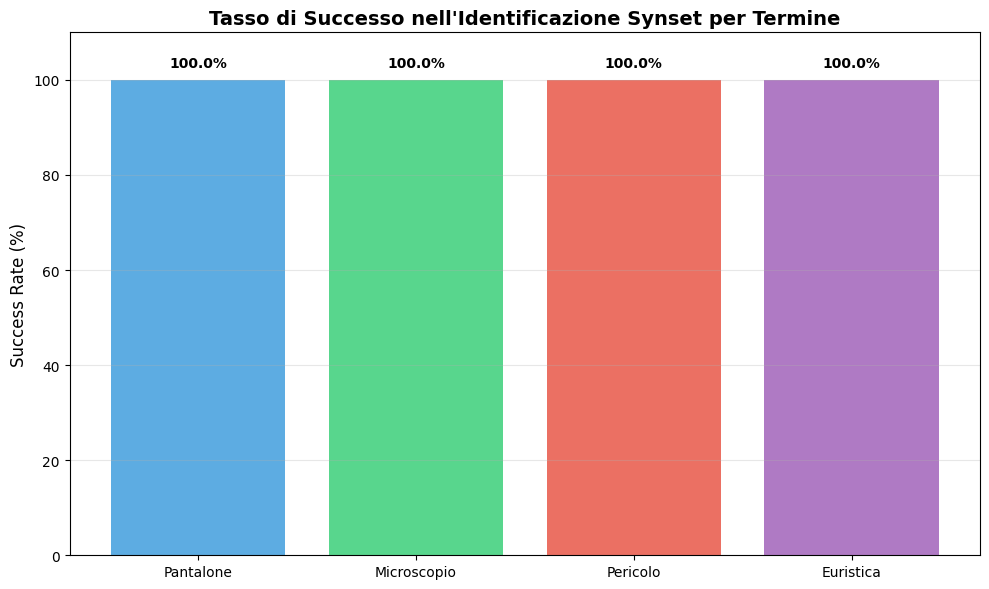

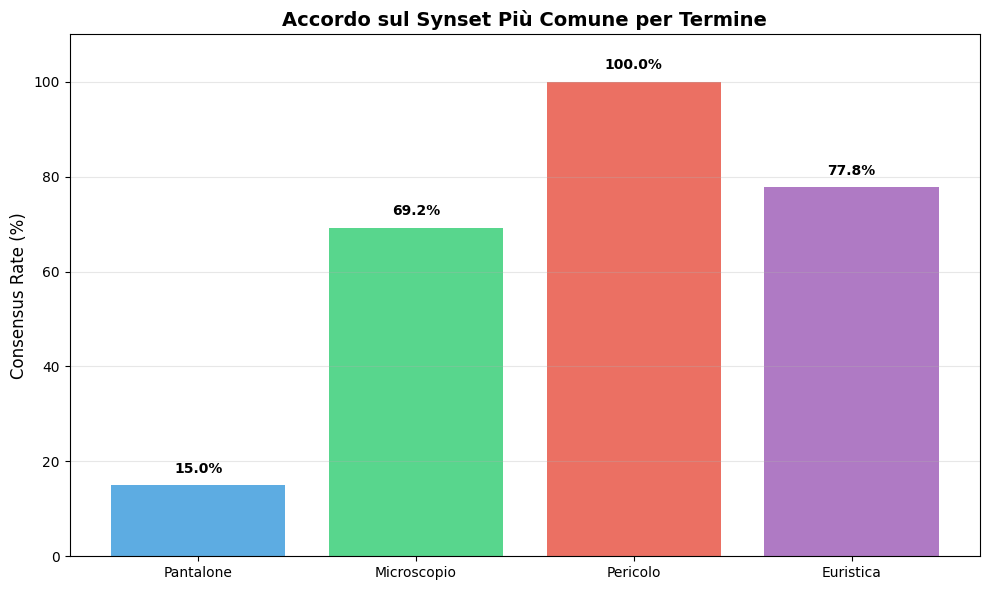

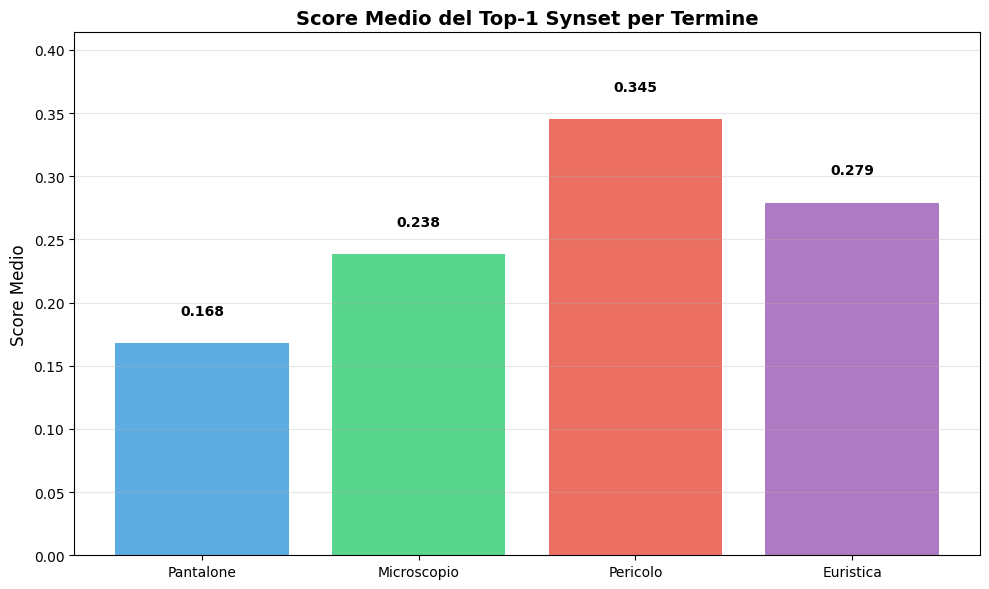

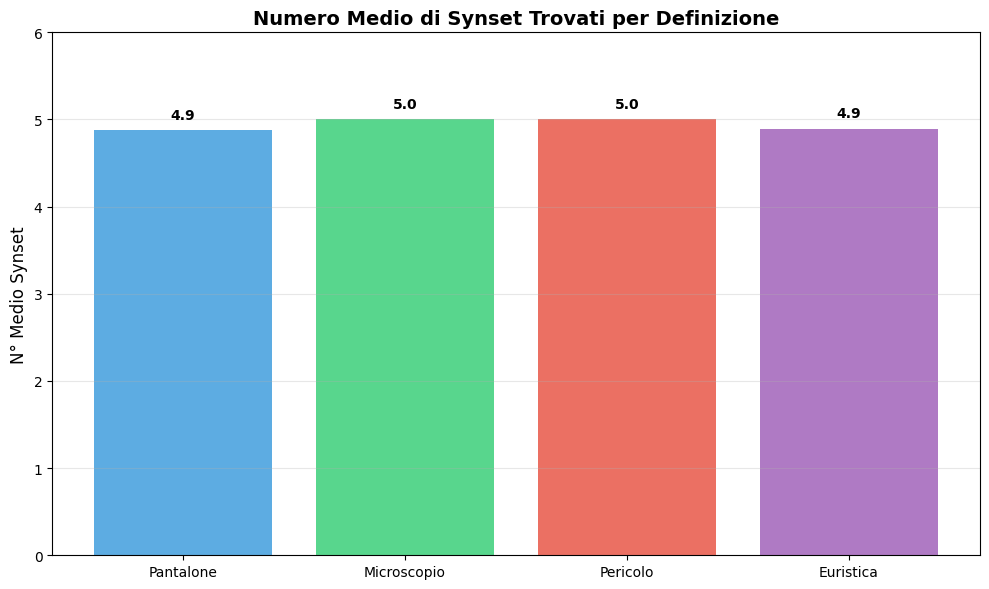

In [ ]:
print("\n" + "="*80)
print("FASE 4: VISUALIZZAZIONI")
print("="*80)

# GRAFICO 1: Success Rate per termine
fig, ax = plt.subplots(figsize=(10, 6))

terms = list(evaluation_metrics.keys())
success_rates = [evaluation_metrics[t]['success_rate'] for t in terms]

bars = ax.bar(terms, success_rates, color=['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'], alpha=0.8)
ax.set_ylabel('Success Rate (%)', fontsize=12)
ax.set_title('Tasso di Successo nell\'Identificazione Synset per Termine', fontsize=14, fontweight='bold')
ax.set_ylim(0, 110)
ax.grid(axis='y', alpha=0.3)

for i, (bar, rate) in enumerate(zip(bars, success_rates)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 2,
            f'{rate:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# GRAFICO 2: Consensus Rate
fig, ax = plt.subplots(figsize=(10, 6))

consensus_rates = [evaluation_metrics[t]['consensus_rate'] for t in terms]

bars = ax.bar(terms, consensus_rates, color=['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'], alpha=0.8)
ax.set_ylabel('Consensus Rate (%)', fontsize=12)
ax.set_title('Accordo sul Synset Più Comune per Termine', fontsize=14, fontweight='bold')
ax.set_ylim(0, 110)
ax.grid(axis='y', alpha=0.3)

for i, (bar, rate) in enumerate(zip(bars, consensus_rates)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 2,
            f'{rate:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# GRAFICO 3: Score Medio Top-1
fig, ax = plt.subplots(figsize=(10, 6))

avg_scores = [evaluation_metrics[t]['avg_top_score'] for t in terms]

bars = ax.bar(terms, avg_scores, color=['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'], alpha=0.8)
ax.set_ylabel('Score Medio', fontsize=12)
ax.set_title('Score Medio del Top-1 Synset per Termine', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(avg_scores) * 1.2 if avg_scores else 1)
ax.grid(axis='y', alpha=0.3)

for i, (bar, score) in enumerate(zip(bars, avg_scores)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
            f'{score:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# GRAFICO 4: Numero medio synset trovati
fig, ax = plt.subplots(figsize=(10, 6))

avg_synsets = [evaluation_metrics[t]['avg_synsets_found'] for t in terms]

bars = ax.bar(terms, avg_synsets, color=['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'], alpha=0.8)
ax.set_ylabel('N° Medio Synset', fontsize=12)
ax.set_title('Numero Medio di Synset Trovati per Definizione', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(avg_synsets) * 1.2 if avg_synsets else 1)
ax.grid(axis='y', alpha=0.3)

for i, (bar, num) in enumerate(zip(bars, avg_synsets)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.1,
            f'{num:.1f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()